<a href="https://colab.research.google.com/github/iipingebnaa/Intensive-Big-Data-Analytics-Project/blob/main/03_Visualization%20%26%20Tableau%20Dashboard/Visualization_%26_Tableau.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Deliverable 3:
Petrus Kadhila

Step 1: Install and Import Required Libraries

In [ ]:
# Install libraries required for RetailMart visualizations
!pip install -q pandas numpy matplotlib seaborn plotly pyarrow

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("Visualization libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Visualization libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3


Step 2: Define the dataset paths

In [ ]:
# Define paths for the cleaned RetailMart datasets
transactions_path = "/content/RetailMart_Cleaned/retailmart_transactions_cleaned.csv"
feedback_path = "/content/RetailMart_Cleaned/customer_feedback_cleaned.csv"

print("Transaction dataset path:", transactions_path)
print("Customer feedback dataset path:", feedback_path)

Transaction dataset path: /content/RetailMart_Cleaned/retailmart_transactions_cleaned.csv
Customer feedback dataset path: /content/RetailMart_Cleaned/customer_feedback_cleaned.csv


Step 3: Upload the cleaned datasets

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving customer_feedback_cleaned.csv to customer_feedback_cleaned.csv
Saving retailmart_transactions_cleaned.csv to retailmart_transactions_cleaned.csv


Step 4: Load and Inspect the Datasets

In [ ]:
# Load the cleaned RetailMart datasets
transactions_path = "/content/retailmart_transactions_cleaned.csv"
feedback_path = "/content/customer_feedback_cleaned.csv"

df_transactions = pd.read_csv(transactions_path)
df_feedback = pd.read_csv(feedback_path)

print("TRANSACTIONS DATASET")
print(f"Rows: {len(df_transactions):,}")
print(f"Columns: {len(df_transactions.columns)}")
display(df_transactions.head())

print("\nCUSTOMER FEEDBACK DATASET")
print(f"Rows: {len(df_feedback):,}")
print(f"Columns: {len(df_feedback.columns)}")
display(df_feedback.head())

TRANSACTIONS DATASET
Rows: 973,266
Columns: 15


,transaction_id,customer_id,transaction_date,product_category,product_name,quantity,unit_price,total_amount,store_location,payment_method,customer_age,customer_gender,loyalty_years,num_visits,churn
0,TXN-00000001,9917ffd9-acc9-49fc-8ac1-dbc79420889f,2022-04-03 10:47:06,Clothing,T-Shirt,1,43.13,43.13,"Dallas, TX",Debit Card,49.0,Non-Binary,3,12,No
1,TXN-00000002,0883f296-153c-4b62-ad0d-036c3d3984b5,2021-03-03 09:13:14,Clothing,Dress,1,55.36,55.36,"Denver, CO",Credit Card,65.0,Unknown,0,4,No
2,TXN-00000003,8976c6e4-9042-4de3-8551-0275d0acaa96,2022-03-28 15:37:17,Groceries,Cereal,2,15.42,30.84,"Las Vegas, NV",Mobile Pay,18.0,Male,1,6,No
3,TXN-00000004,287ce01e-0d82-4a1e-b34e-3212e940b9b3,2022-07-24 10:13:48,Home & Kitchen,Dinnerware,1,87.83,87.83,"Denver, CO",Cash,33.0,Male,2,8,No
4,TXN-00000005,b5b5845e-822e-4dbb-a17a-48fb614810e8,2024-05-21 12:51:02,Toys,Action Figure,1,34.94,34.94,"Boston, MA",Cash,33.0,Male,7,16,No



CUSTOMER FEEDBACK DATASET
Rows: 250,000
Columns: 14


,feedback_id,timestamp,platform,device_type,customer_id,customer_name,customer_location,customer_age,customer_loyalty_years,feedback_text,feedback_rating,feedback_sentiment,feedback_product_category,feedback_store_location
0,f31add8b-faea-46c1-8d46-a414db2d2c2d,2022-04-27 14:11:00,Web,Web Browser,8235697e-79b2-46d1-aa2f-00abbb020d95,Allison Hill,"New York, NY",43.0,2,"Products are okay, nothing special.",3,0.129,Beauty,"Houston, TX"
1,8ddc49e6-4a26-4ae0-861c-46f866ecbb5a,2025-02-18 21:47:00,Email,Android,29cf125c-8f5b-47a6-afed-9ac2f65e1ca6,Noah Rhodes,"Atlanta, GA",32.0,9,"Long wait times, won't shop here again.",2,-0.841,Books,"Atlanta, GA"
2,02620440-57b6-407c-ac35-14ab37f550b4,2024-01-12 16:38:00,Web,Tablet,1c7e899f-3b0a-48b0-a493-d0f730b1dd53,Angie Henderson,"Chicago, IL",25.0,0,Okay experience overall.,3,0.258,Books,"Philadelphia, PA"
3,6a6b556d-0bf4-488e-ace1-edf9a5ae6c87,2024-01-08 18:35:00,Phone,iPhone,bd92bbfb-68ba-4f58-a825-068f3059c636,Daniel Wagner,"Las Vegas, NV",45.0,1,"Long wait times, won't shop here again.",1,-0.957,Books,"San Antonio, TX"
4,3c1db7b2-24b1-4890-a9dc-b3f4117e312f,2022-04-06 09:21:00,Mobile App,iPhone,56725236-42a6-44ea-803b-048da063e05b,Cristian Santos,"Denver, CO",55.0,1,"Poor customer service, very disappointed.",1,-0.549,Home & Kitchen,"Denver, CO"


Step 5: Inspect Dataset Structure and Data Types

In [ ]:
# Inspect transaction dataset structure
print("TRANSACTIONS DATASET")
df_transactions.info()

print("\nTransaction column names:")
print(df_transactions.columns.tolist())

# Inspect customer feedback dataset structure
print("\nCUSTOMER FEEDBACK DATASET")
df_feedback.info()

print("\nFeedback column names:")
print(df_feedback.columns.tolist())

TRANSACTIONS DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973266 entries, 0 to 973265
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    973266 non-null  object 
 1   customer_id       973266 non-null  object 
 2   transaction_date  973266 non-null  object 
 3   product_category  973266 non-null  object 
 4   product_name      973266 non-null  object 
 5   quantity          973266 non-null  int64  
 6   unit_price        973266 non-null  float64
 7   total_amount      973266 non-null  float64
 8   store_location    973266 non-null  object 
 9   payment_method    973266 non-null  object 
 10  customer_age      973266 non-null  float64
 11  customer_gender   973266 non-null  object 
 12  loyalty_years     973266 non-null  int64  
 13  num_visits        973266 non-null  int64  
 14  churn             973266 non-null  object 
dtypes: float64(3), int64(3), object(9)
memory usage

Step 6: Prepare Data Types for Visualization

In [ ]:
# Convert date columns to datetime format
df_transactions["transaction_date"] = pd.to_datetime(
    df_transactions["transaction_date"], errors="coerce"
)

df_feedback["timestamp"] = pd.to_datetime(
    df_feedback["timestamp"], errors="coerce"
)

# Confirm the conversions
print("Transaction date type:", df_transactions["transaction_date"].dtype)
print("Feedback timestamp type:", df_feedback["timestamp"].dtype)

print("\nInvalid transaction dates:", df_transactions["transaction_date"].isna().sum())
print("Invalid feedback timestamps:", df_feedback["timestamp"].isna().sum())

Transaction date type: datetime64[ns]
Feedback timestamp type: datetime64[ns]

Invalid transaction dates: 0
Invalid feedback timestamps: 0


Step 7: Generate Descriptive Statistics

In [ ]:
# Descriptive statistics for transaction data
transaction_numeric_cols = [
    "quantity",
    "unit_price",
    "total_amount",
    "customer_age",
    "loyalty_years",
    "num_visits"
]

print("TRANSACTION DATA: DESCRIPTIVE STATISTICS")
display(df_transactions[transaction_numeric_cols].describe().round(2))

# Descriptive statistics for customer feedback data
feedback_numeric_cols = [
    "customer_age",
    "customer_loyalty_years",
    "feedback_rating",
    "feedback_sentiment"
]

print("CUSTOMER FEEDBACK: DESCRIPTIVE STATISTICS")
display(df_feedback[feedback_numeric_cols].describe().round(2))

TRANSACTION DATA: DESCRIPTIVE STATISTICS


,quantity,unit_price,total_amount,customer_age,loyalty_years,num_visits
count,973266.00,973266.00,973266.00,973266.00,973266.00,973266.00
mean,2.54,68.19,172.50,41.83,2.44,9.88
std,1.98,78.87,286.26,14.00,2.65,6.17
min,1.00,5.00,5.00,18.00,0.00,1.00
25%,1.00,19.95,35.72,32.00,0.00,5.00
50%,2.00,38.56,78.16,41.00,2.00,8.00
75%,3.00,79.57,187.00,51.00,4.00,13.00
max,20.00,574.33,7565.40,85.00,10.00,46.00


CUSTOMER FEEDBACK: DESCRIPTIVE STATISTICS


,customer_age,customer_loyalty_years,feedback_rating,feedback_sentiment
count,250000.00,250000.00,250000.00,250000.00
mean,43.26,2.52,3.00,0.00
std,13.01,2.99,1.32,0.58
min,18.00,0.00,1.00,-1.00
25%,34.00,0.00,2.00,-0.50
50%,43.00,2.00,3.00,0.00
75%,52.00,4.00,4.00,0.50
max,109.00,37.00,5.00,1.00


Step 8: Analyze Sales by Product Category

Sales Revenue by Product Category:


,product_category,total_revenue,transaction_count
0,Electronics,76730107.65,121969
1,Home & Kitchen,26142649.33,121487
2,Sports,23173433.23,121982
3,Clothing,13877305.47,121437
4,Toys,10866525.17,122055
5,Beauty,7740414.52,121192
6,Books,5565929.00,121361
7,Groceries,3788130.85,121783


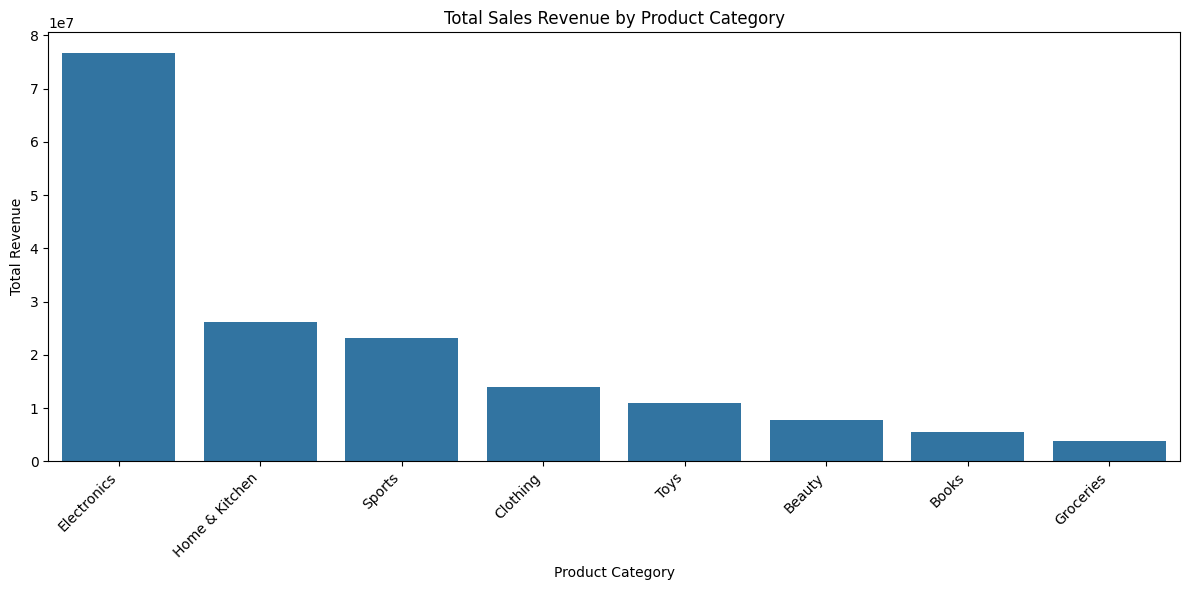

In [ ]:
# Calculate revenue and transaction count by product category
category_sales = (
    df_transactions.groupby("product_category")
    .agg(
        total_revenue=("total_amount", "sum"),
        transaction_count=("transaction_id", "count")
    )
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)

print("Sales Revenue by Product Category:")
display(category_sales.round(2))

# Plot total revenue by product category
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_sales,
    x="product_category",
    y="total_revenue"
)

plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.title("Total Sales Revenue by Product Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Step 9: Analyze Sales by Store Location

Sales Performance by Store Location:


,store_location,total_revenue,transaction_count,average_transaction_value
0,"San Diego, CA",8486718.20,48392,175.37
1,"Dallas, TX",8465119.45,48625,174.09
2,"Miami, FL",8456227.25,48437,174.58
3,"Las Vegas, NV",8430988.41,48276,174.64
4,"Chicago, IL",8411780.95,48768,172.49
5,"Seattle, WA",8411142.75,48486,173.48
6,"Boston, MA",8389385.32,48544,172.82
7,"New York, NY",8380244.97,48563,172.56
8,"Minneapolis, MN",8363957.81,48531,172.34
9,"Denver, CO",8356075.93,48036,173.95


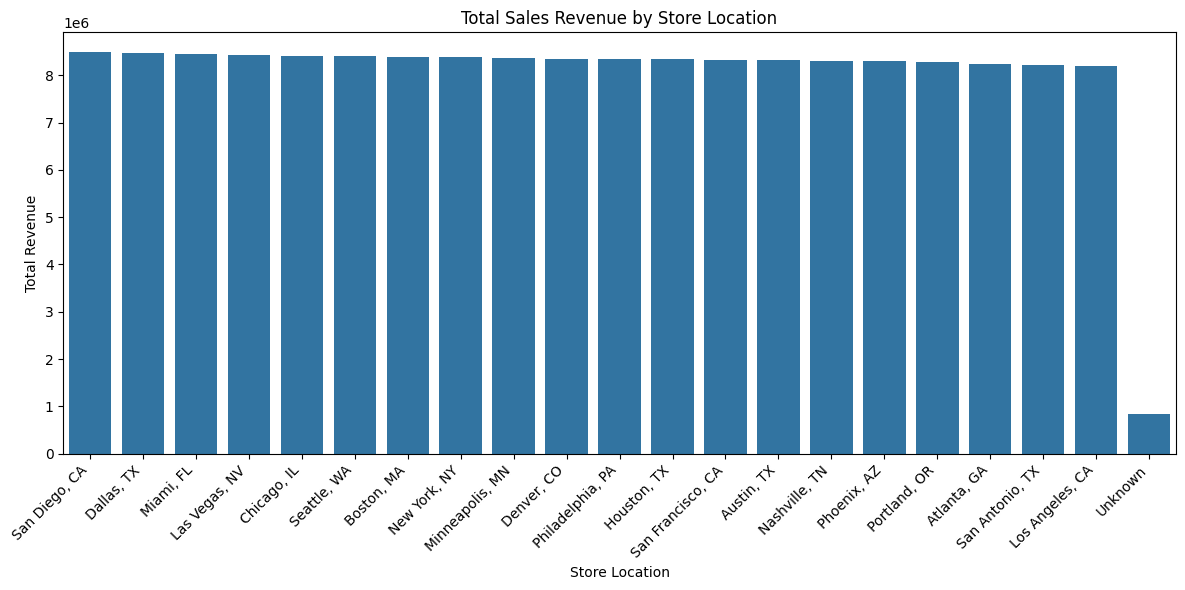

In [ ]:
# Calculate revenue and transaction volume by store
store_sales = (
    df_transactions.groupby("store_location")
    .agg(
        total_revenue=("total_amount", "sum"),
        transaction_count=("transaction_id", "count"),
        average_transaction_value=("total_amount", "mean")
    )
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)

print("Sales Performance by Store Location:")
display(store_sales.round(2))

# Plot revenue by store location
plt.figure(figsize=(12, 6))

sns.barplot(
    data=store_sales,
    x="store_location",
    y="total_revenue"
)

plt.xlabel("Store Location")
plt.ylabel("Total Revenue")
plt.title("Total Sales Revenue by Store Location")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Step 10: Analyze Monthly Sales Trends

First 10 months of sales data:


,transaction_month,total_revenue,transaction_count
0,2021-01,2583837.84,14940
1,2021-02,2287512.52,13454
2,2021-03,2537356.59,14866
3,2021-04,2371069.80,14180
4,2021-05,2553814.23,14879
5,2021-06,2506793.93,14718
6,2021-07,2584285.71,14928
7,2021-08,2509651.93,14700
8,2021-09,2459329.62,14249
9,2021-10,2565171.10,14837


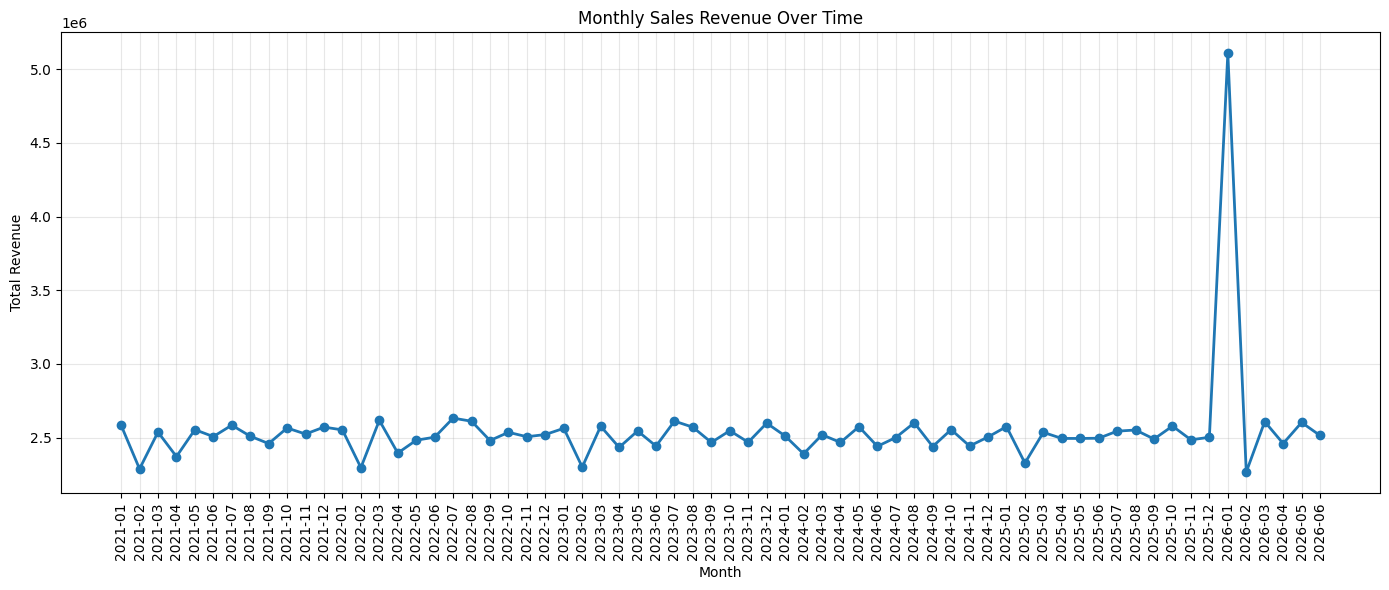

In [ ]:
# Extract year and month from transaction dates
df_transactions["transaction_month"] = (
    df_transactions["transaction_date"].dt.to_period("M").astype(str)
)

# Summarise monthly sales
monthly_sales = (
    df_transactions.groupby("transaction_month")
    .agg(
        total_revenue=("total_amount", "sum"),
        transaction_count=("transaction_id", "count")
    )
    .reset_index()
    .sort_values("transaction_month")
)

print("First 10 months of sales data:")
display(monthly_sales.head(10).round(2))

# Plot monthly revenue
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["transaction_month"],
    monthly_sales["total_revenue"],
    marker="o",
    linewidth=2
)

plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.title("Monthly Sales Revenue Over Time")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Step 11: Analyze Payment Methods

Payment Method Analysis:


,payment_method,transaction_count,total_revenue,transaction_percentage
4,Mobile Pay,189978,32843583.13,19.52
0,Cash,189781,32769654.16,19.50
3,Gift Card,189757,32637733.64,19.50
1,Credit Card,189660,32767134.98,19.49
2,Debit Card,189652,32629972.71,19.49
5,Unknown,24438,4236416.60,2.51


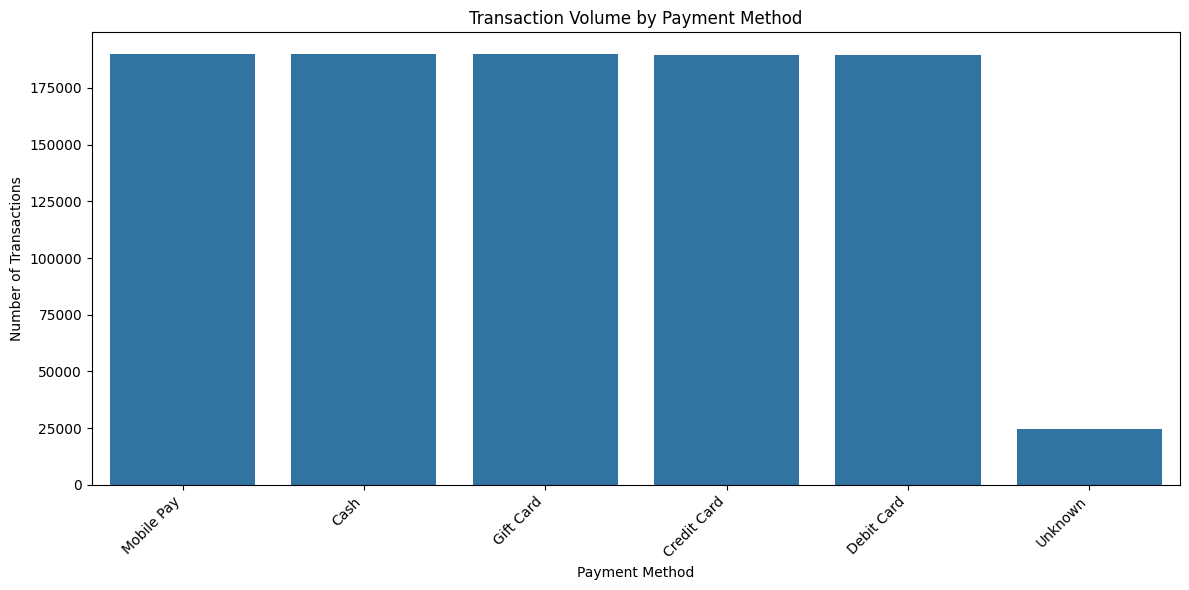

In [ ]:
# Summarise transactions by payment method
payment_analysis = (
    df_transactions.groupby("payment_method")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_revenue=("total_amount", "sum")
    )
    .reset_index()
    .sort_values("transaction_count", ascending=False)
)

# Calculate percentage of transactions per payment method
payment_analysis["transaction_percentage"] = (
    payment_analysis["transaction_count"]
    / payment_analysis["transaction_count"].sum()
    * 100
)

print("Payment Method Analysis:")
display(payment_analysis.round(2))

# Plot transaction count by payment method
plt.figure(figsize=(12, 6))

sns.barplot(
    data=payment_analysis,
    x="payment_method",
    y="transaction_count"
)

plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.title("Transaction Volume by Payment Method")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Step 12: Analyze Customer Age and Gender

Transaction Summary by Gender:


,customer_gender,transaction_count,total_revenue,average_transaction_value
1,Male,308223,52971849.97,171.86
0,Female,307761,53001327.54,172.22
2,Non-Binary,306555,53185570.75,173.49
3,Unknown,50727,8725746.96,172.01


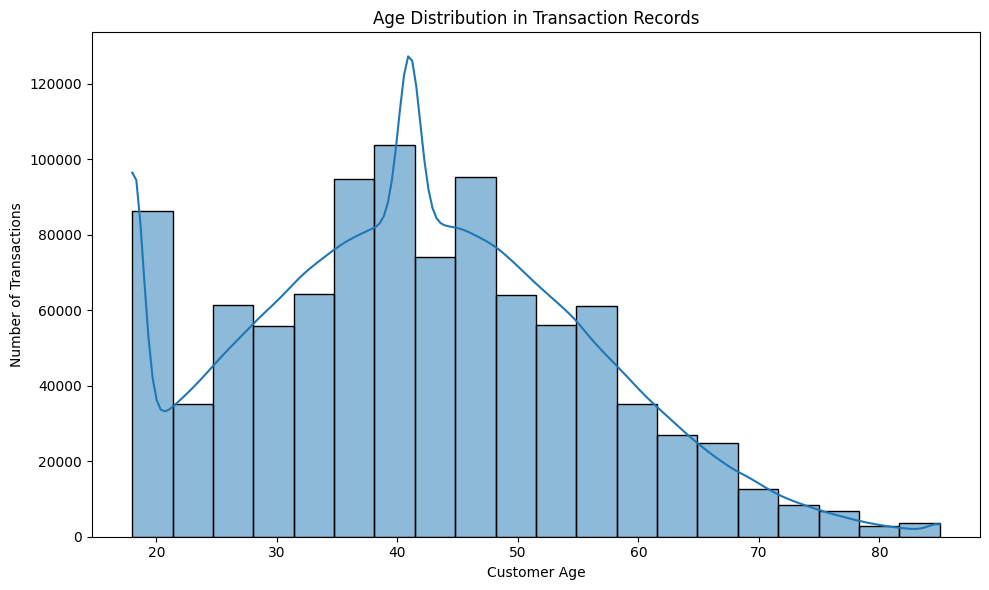

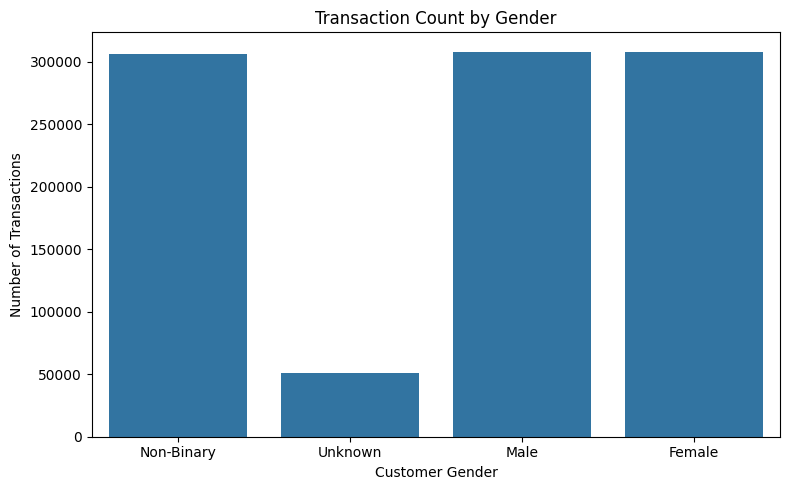

In [ ]:
# Summarise transactions by gender
gender_analysis = (
    df_transactions.groupby("customer_gender")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_revenue=("total_amount", "sum"),
        average_transaction_value=("total_amount", "mean")
    )
    .reset_index()
    .sort_values("transaction_count", ascending=False)
)

print("Transaction Summary by Gender:")
display(gender_analysis.round(2))

# Plot customer age distribution
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df_transactions,
    x="customer_age",
    bins=20,
    kde=True
)
plt.xlabel("Customer Age")
plt.ylabel("Number of Transactions")
plt.title("Age Distribution in Transaction Records")
plt.tight_layout()
plt.show()

# Plot transaction count by gender
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_transactions,
    x="customer_gender"
)
plt.xlabel("Customer Gender")
plt.ylabel("Number of Transactions")
plt.title("Transaction Count by Gender")
plt.tight_layout()
plt.show()

Step 13: Analyze Churn Distribution

Churn Distribution:


,churn,transaction_count,percentage
0,No,755929,77.67
1,Yes,217337,22.33


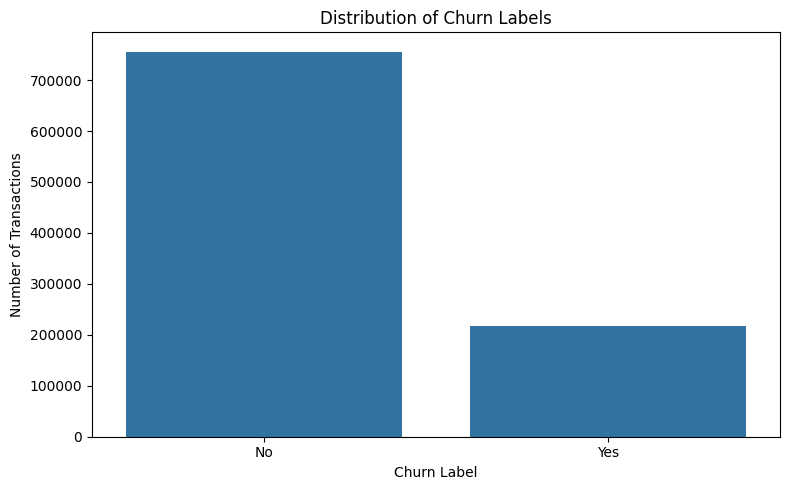

In [ ]:
# Count records in each churn category
churn_analysis = (
    df_transactions["churn"]
    .value_counts(dropna=False)
    .reset_index()
)

churn_analysis.columns = ["churn", "transaction_count"]

# Calculate percentage of records in each category
churn_analysis["percentage"] = (
    churn_analysis["transaction_count"]
    / churn_analysis["transaction_count"].sum()
    * 100
)

print("Churn Distribution:")
display(churn_analysis.round(2))

# Plot churn distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_transactions,
    x="churn",
    order=df_transactions["churn"].value_counts().index
)

plt.xlabel("Churn Label")
plt.ylabel("Number of Transactions")
plt.title("Distribution of Churn Labels")
plt.tight_layout()
plt.show()

Step 14: Analyze Customer Feedback Ratings

Customer Feedback Rating Distribution:


,rating,feedback_count,percentage
0,1,43808,17.52
1,2,43531,17.41
2,3,75314,30.13
3,4,43256,17.30
4,5,44091,17.64



Average feedback rating: 3.0 out of 5


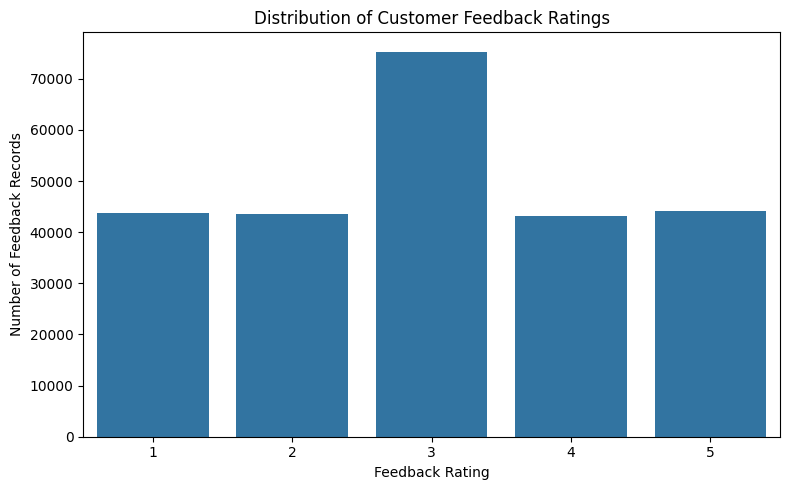

In [ ]:
# Summarise feedback ratings
rating_analysis = (
    df_feedback["feedback_rating"]
    .value_counts()
    .sort_index()
    .reset_index()
)

rating_analysis.columns = ["rating", "feedback_count"]

rating_analysis["percentage"] = (
    rating_analysis["feedback_count"]
    / rating_analysis["feedback_count"].sum()
    * 100
)

print("Customer Feedback Rating Distribution:")
display(rating_analysis.round(2))

print(
    "\nAverage feedback rating:",
    round(df_feedback["feedback_rating"].mean(), 2),
    "out of 5"
)

# Plot feedback rating distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_feedback,
    x="feedback_rating",
    order=sorted(df_feedback["feedback_rating"].dropna().unique())
)

plt.xlabel("Feedback Rating")
plt.ylabel("Number of Feedback Records")
plt.title("Distribution of Customer Feedback Ratings")
plt.tight_layout()
plt.show()

Step 15: Compare Feedback Sentiment Across Product Categories

Feedback Sentiment by Product Category:


,feedback_product_category,feedback_count,average_sentiment,median_sentiment,average_rating
0,Beauty,30690,0.006,0.011,3.013
5,Home & Kitchen,31119,0.004,0.004,3.009
6,Sports,31335,0.002,0.002,3.005
1,Books,31496,0.001,0.002,3.004
3,Electronics,31563,-0.001,-0.003,3.006
2,Clothing,30958,-0.003,-0.006,2.988
7,Toys,31338,-0.003,-0.010,2.995
4,Groceries,31501,-0.004,-0.005,2.989


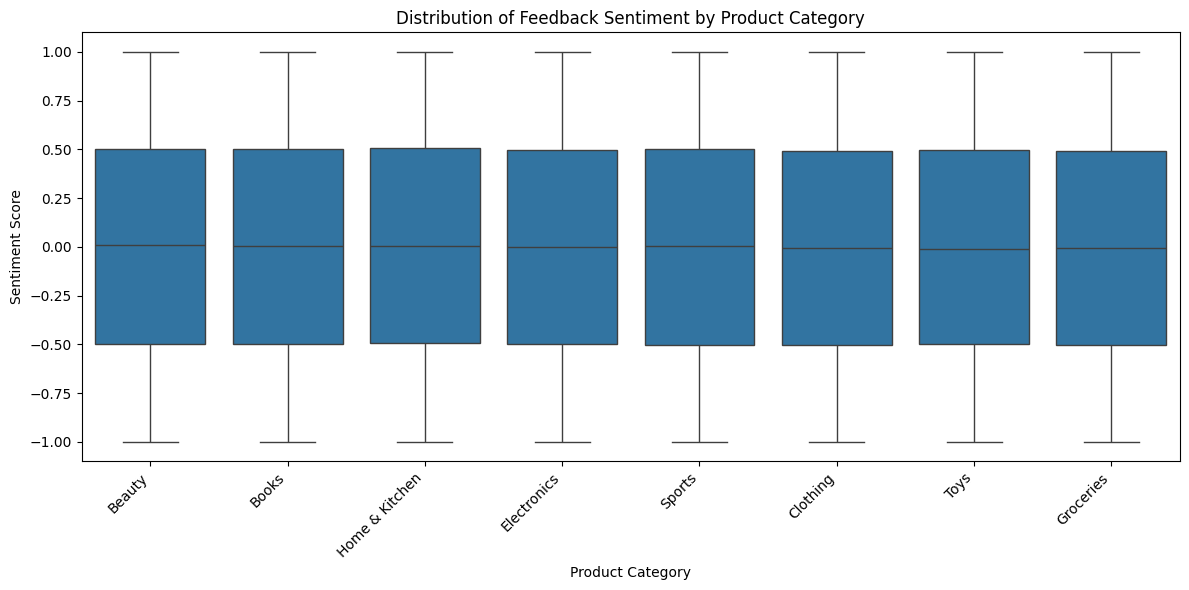

In [ ]:
# Summarise feedback by product category
sentiment_by_category = (
    df_feedback.groupby("feedback_product_category")
    .agg(
        feedback_count=("feedback_sentiment", "count"),
        average_sentiment=("feedback_sentiment", "mean"),
        median_sentiment=("feedback_sentiment", "median"),
        average_rating=("feedback_rating", "mean")
    )
    .reset_index()
    .sort_values("average_sentiment", ascending=False)
)

print("Feedback Sentiment by Product Category:")
display(sentiment_by_category.round(3))

# Compare sentiment distributions using a box plot
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_feedback,
    x="feedback_product_category",
    y="feedback_sentiment"
)

plt.xlabel("Product Category")
plt.ylabel("Sentiment Score")
plt.title("Distribution of Feedback Sentiment by Product Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Step 16: Relationship Between Quantity and Transaction Value

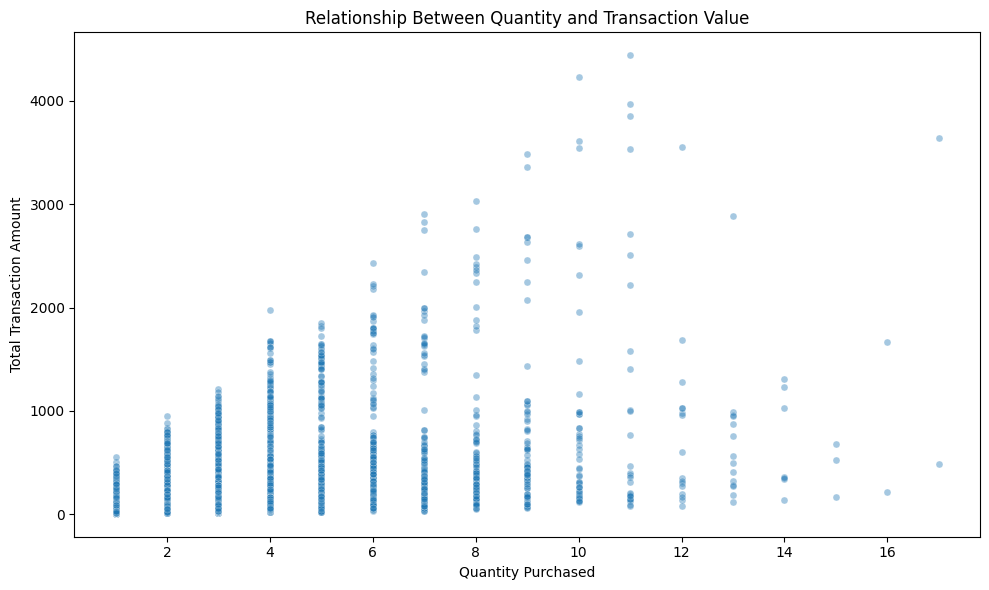

Correlation between quantity and total transaction amount: 0.467


In [ ]:
# Draw a sample to make the scatter plot easier to read
scatter_sample = df_transactions.sample(
    n=min(10000, len(df_transactions)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=scatter_sample,
    x="quantity",
    y="total_amount",
    alpha=0.4,
    s=25
)

plt.xlabel("Quantity Purchased")
plt.ylabel("Total Transaction Amount")
plt.title("Relationship Between Quantity and Transaction Value")
plt.tight_layout()
plt.show()

# Calculate the correlation between quantity and transaction value
quantity_value_corr = df_transactions[
    ["quantity", "total_amount"]
].corr().iloc[0, 1]

print(
    "Correlation between quantity and total transaction amount:",
    round(quantity_value_corr, 3)
)

Step 17: Correlation Heatmap

Correlation Matrix:


,quantity,unit_price,total_amount,customer_age,loyalty_years,num_visits
quantity,1.00,0.00,0.47,0.0,-0.00,-0.00
unit_price,0.00,1.00,0.69,-0.0,0.00,0.00
total_amount,0.47,0.69,1.00,0.0,0.00,0.00
customer_age,0.00,-0.00,0.00,1.0,0.00,-0.00
loyalty_years,-0.00,0.00,0.00,0.0,1.00,0.86
num_visits,-0.00,0.00,0.00,-0.0,0.86,1.00


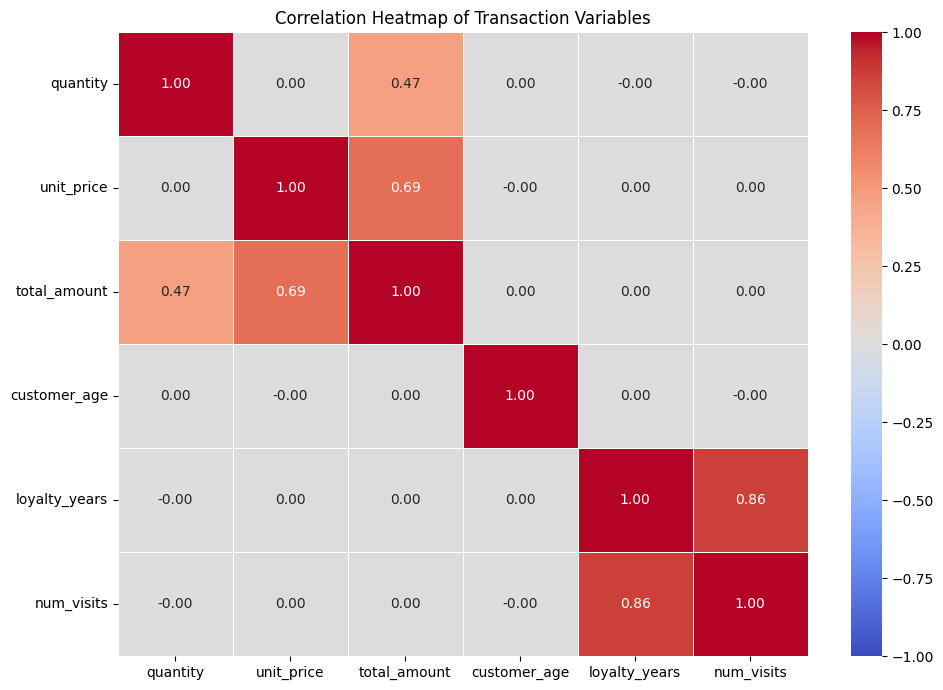

In [ ]:
# Select numerical variables for correlation analysis
correlation_cols = [
    "quantity",
    "unit_price",
    "total_amount",
    "customer_age",
    "loyalty_years",
    "num_visits"
]

correlation_matrix = df_transactions[correlation_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

# Plot the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Transaction Variables")
plt.tight_layout()
plt.show()

Step 18: Feedback Analysis by Platform

This section compares feedback volume and average ratings across platforms. It examines whether the generated feedback data differs in activity or average rating by platform. The analysis may help identify which platforms contribute the most feedback, while recognising that the data is synthetic.

Feedback Summary by Platform:


,platform,feedback_count,average_rating,average_sentiment
3,Phone,50275,2.995,-0.003
2,Mobile App,50000,2.999,0.000
0,Email,49933,3.003,0.000
1,In-Store,49898,3.006,0.001
4,Web,49894,3.003,0.002


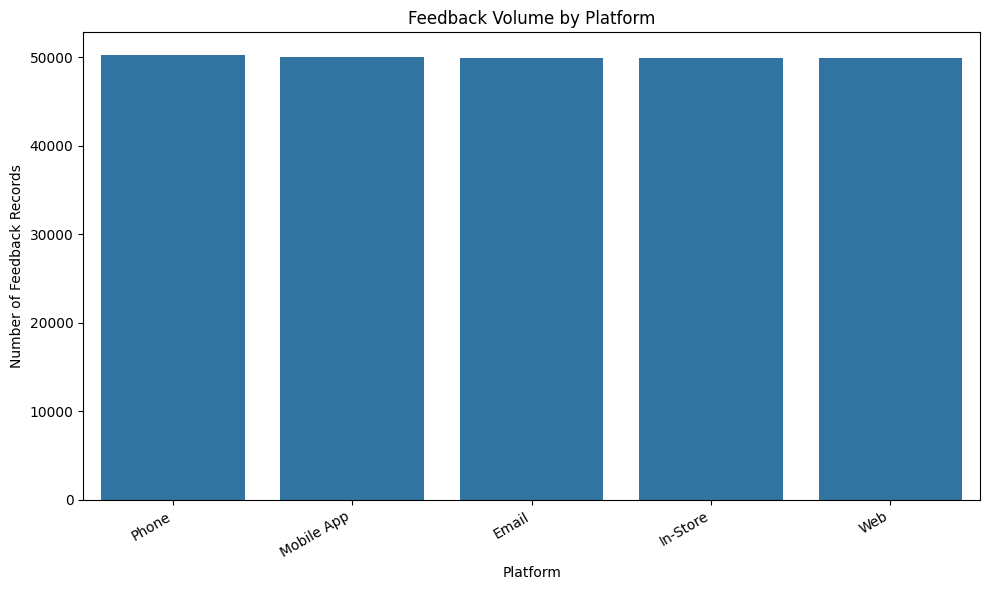

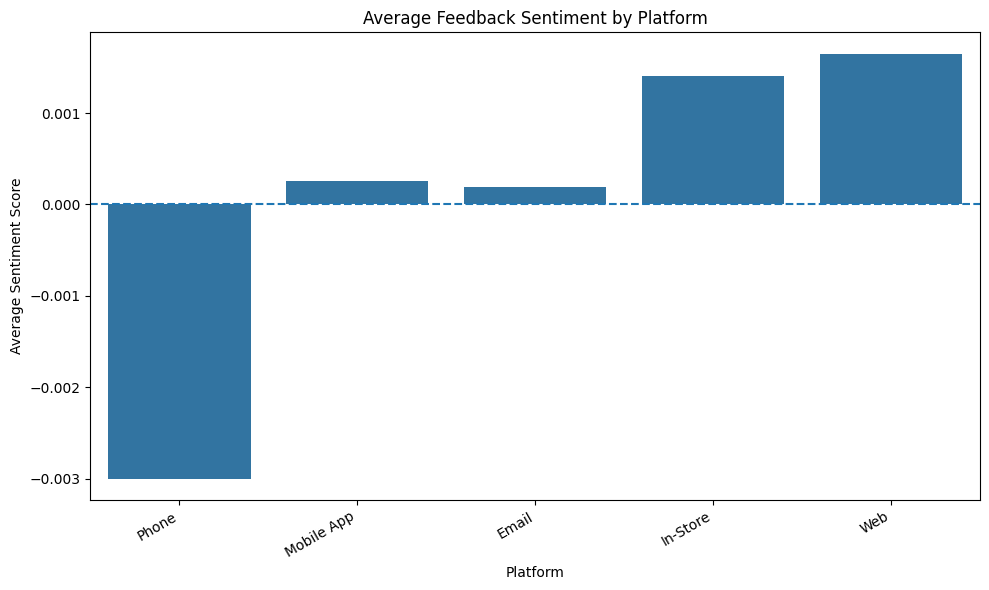

In [ ]:
# Summarise feedback by platform
platform_analysis = (
    df_feedback.groupby("platform")
    .agg(
        feedback_count=("feedback_id", "count"),
        average_rating=("feedback_rating", "mean"),
        average_sentiment=("feedback_sentiment", "mean")
    )
    .reset_index()
    .sort_values("feedback_count", ascending=False)
)

print("Feedback Summary by Platform:")
display(platform_analysis.round(3))

# Plot feedback volume by platform
plt.figure(figsize=(10, 6))

sns.barplot(
    data=platform_analysis,
    x="platform",
    y="feedback_count"
)

plt.xlabel("Platform")
plt.ylabel("Number of Feedback Records")
plt.title("Feedback Volume by Platform")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Plot average sentiment by platform
plt.figure(figsize=(10, 6))

sns.barplot(
    data=platform_analysis,
    x="platform",
    y="average_sentiment"
)

plt.axhline(0, linestyle="--")
plt.xlabel("Platform")
plt.ylabel("Average Sentiment Score")
plt.title("Average Feedback Sentiment by Platform")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Step 19: Compare Average Transaction Value Across Product Categories

Transaction Value Summary by Product Category:


,product_category,transaction_count,average_transaction_value,median_transaction_value,total_revenue
3,Electronics,121969,629.10,445.26,76730107.65
5,Home & Kitchen,121487,215.19,151.54,26142649.33
6,Sports,121982,189.97,134.49,23173433.23
2,Clothing,121437,114.28,80.64,13877305.47
7,Toys,122055,89.03,64.28,10866525.17
0,Beauty,121192,63.87,46.04,7740414.52
1,Books,121361,45.86,33.12,5565929.00
4,Groceries,121783,31.11,22.18,3788130.85


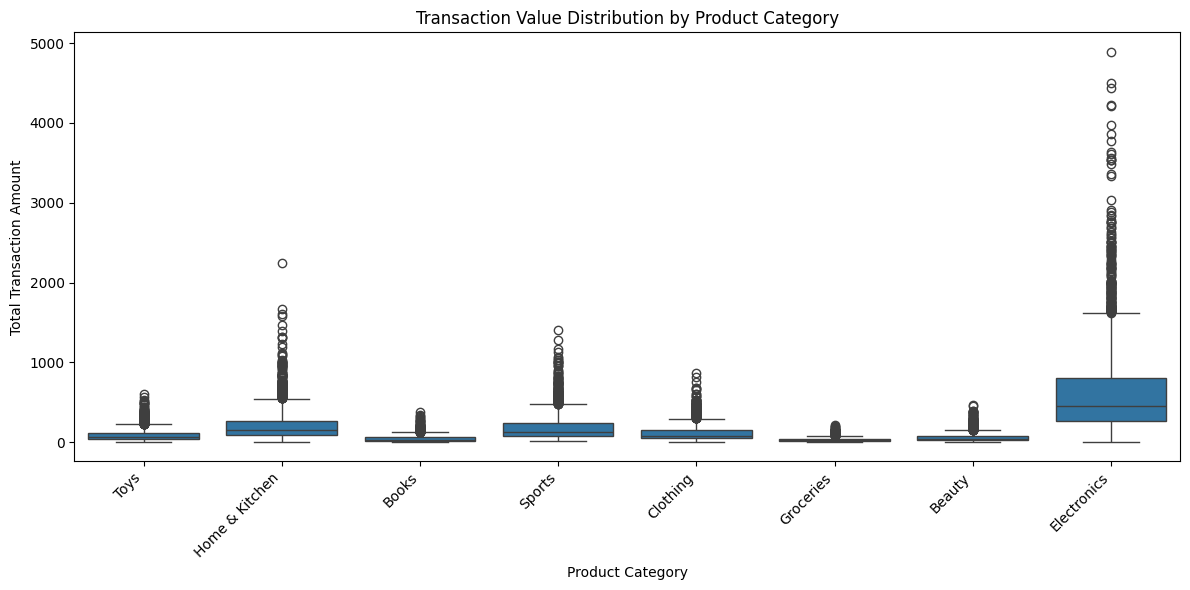

In [ ]:
# Summarise transaction values by product category
category_transaction_analysis = (
    df_transactions.groupby("product_category")
    .agg(
        transaction_count=("transaction_id", "count"),
        average_transaction_value=("total_amount", "mean"),
        median_transaction_value=("total_amount", "median"),
        total_revenue=("total_amount", "sum")
    )
    .reset_index()
    .sort_values("median_transaction_value", ascending=False)
)

print("Transaction Value Summary by Product Category:")
display(category_transaction_analysis.round(2))

# Sample records for a clearer box plot
boxplot_sample = df_transactions.sample(
    n=min(20000, len(df_transactions)),
    random_state=42
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=boxplot_sample,
    x="product_category",
    y="total_amount"
)

plt.xlabel("Product Category")
plt.ylabel("Total Transaction Amount")
plt.title("Transaction Value Distribution by Product Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Step 20: Prepare Tableau Summary Datasets

In [ ]:
# 1. Sales by product category
tableau_category_sales = (
    df_transactions.groupby("product_category")
    .agg(
        total_revenue=("total_amount", "sum"),
        transaction_count=("transaction_id", "count"),
        average_transaction_value=("total_amount", "mean")
    )
    .reset_index()
)

# 2. Sales by store location
tableau_store_sales = (
    df_transactions.groupby("store_location")
    .agg(
        total_revenue=("total_amount", "sum"),
        transaction_count=("transaction_id", "count"),
        average_transaction_value=("total_amount", "mean")
    )
    .reset_index()
)

# 3. Monthly sales
tableau_monthly_sales = (
    df_transactions.groupby("transaction_month")
    .agg(
        total_revenue=("total_amount", "sum"),
        transaction_count=("transaction_id", "count")
    )
    .reset_index()
    .sort_values("transaction_month")
)

# 4. Sales by payment method
tableau_payment_sales = (
    df_transactions.groupby("payment_method")
    .agg(
        total_revenue=("total_amount", "sum"),
        transaction_count=("transaction_id", "count")
    )
    .reset_index()
)

# 5. Churn-label summary
tableau_churn = (
    df_transactions.groupby("churn", dropna=False)
    .size()
    .reset_index(name="record_count")
)

tableau_churn["percentage"] = (
    tableau_churn["record_count"]
    / tableau_churn["record_count"].sum()
    * 100
)

# 6. Feedback summary by platform
tableau_feedback_platform = (
    df_feedback.groupby("platform")
    .agg(
        feedback_count=("feedback_id", "count"),
        average_rating=("feedback_rating", "mean"),
        average_sentiment=("feedback_sentiment", "mean")
    )
    .reset_index()
)

# 7. Feedback summary by product category
tableau_feedback_category = (
    df_feedback.groupby("feedback_product_category")
    .agg(
        feedback_count=("feedback_id", "count"),
        average_rating=("feedback_rating", "mean"),
        average_sentiment=("feedback_sentiment", "mean")
    )
    .reset_index()
)

print("Tableau summary datasets created successfully.")

print("\nSales by category:")
display(tableau_category_sales.round(2))

print("\nSales by store:")
display(tableau_store_sales.round(2))

print("\nMonthly sales sample:")
display(tableau_monthly_sales.head().round(2))

print("\nSales by payment method:")
display(tableau_payment_sales.round(2))

print("\nChurn-label summary:")
display(tableau_churn.round(2))

print("\nFeedback by platform:")
display(tableau_feedback_platform.round(3))

print("\nFeedback by category:")
display(tableau_feedback_category.round(3))

Tableau summary datasets created successfully.

Sales by category:


,product_category,total_revenue,transaction_count,average_transaction_value
0,Beauty,7740414.52,121192,63.87
1,Books,5565929.00,121361,45.86
2,Clothing,13877305.47,121437,114.28
3,Electronics,76730107.65,121969,629.10
4,Groceries,3788130.85,121783,31.11
5,Home & Kitchen,26142649.33,121487,215.19
6,Sports,23173433.23,121982,189.97
7,Toys,10866525.17,122055,89.03



Sales by store:


,store_location,total_revenue,transaction_count,average_transaction_value
0,"Atlanta, GA",8250267.18,47993,171.91
1,"Austin, TX",8316765.36,48465,171.60
2,"Boston, MA",8389385.32,48544,172.82
3,"Chicago, IL",8411780.95,48768,172.49
4,"Dallas, TX",8465119.45,48625,174.09
5,"Denver, CO",8356075.93,48036,173.95
6,"Houston, TX",8351419.66,48288,172.95
7,"Las Vegas, NV",8430988.41,48276,174.64
8,"Los Angeles, CA",8194954.94,48544,168.81
9,"Miami, FL",8456227.25,48437,174.58



Monthly sales sample:


...

,churn,record_count,percentage
0,No,755929,77.67
1,Yes,217337,22.33



Feedback by platform:


,platform,feedback_count,average_rating,average_sentiment
0,Email,49933,3.003,0.000
1,In-Store,49898,3.006,0.001
2,Mobile App,50000,2.999,0.000
3,Phone,50275,2.995,-0.003
4,Web,49894,3.003,0.002



Feedback by category:


,feedback_product_category,feedback_count,average_rating,average_sentiment
0,Beauty,30690,3.013,0.006
1,Books,31496,3.004,0.001
2,Clothing,30958,2.988,-0.003
3,Electronics,31563,3.006,-0.001
4,Groceries,31501,2.989,-0.004
5,Home & Kitchen,31119,3.009,0.004
6,Sports,31335,3.005,0.002
7,Toys,31338,2.995,-0.003
